# Exploratory Data Analysis — Wine Quality Dataset

Цель анализа — понять структуру датасета, качество данных, распределения признаков и их связь с оценкой вина `quality`. EDA помогает принять решения о дальнейшей очистке данных и подготовке модели.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

plt.rcParams["figure.figsize"] = (8, 5)
sns.set_theme(style="whitegrid")

## Загрузка и первичный просмотр

Сначала проверим первые строки, размер таблицы и типы данных.

In [2]:
df = pd.read_csv("WineQT.csv")
display(df.head())
print(f"Размер датасета: {df.shape[0]} строк, {df.shape[1]} столбцов")
df.info()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


Размер датасета: 1143 строк, 13 столбцов
<class 'pandas.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null   float64
 11  quality               1143 non-null   int64  
 12  Id                    1143 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 116.2 KB


## Качество данных

Проверяем пропуски, полные дубликаты и уникальные значения. Дубликаты могут влиять на статистику и обучение модели.

In [3]:
print("Пропуски по столбцам:")
display(df.isna().sum().to_frame("missing"))
print("Количество полных дубликатов:", df.duplicated().sum())

for col in df.columns:
    print(f"{col}: {df[col].nunique()} уникальных значений")

Пропуски по столбцам:


,missing
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


Количество полных дубликатов: 0
fixed acidity: 91 уникальных значений
volatile acidity: 135 уникальных значений
citric acid: 77 уникальных значений
residual sugar: 80 уникальных значений
chlorides: 131 уникальных значений
free sulfur dioxide: 53 уникальных значений
total sulfur dioxide: 138 уникальных значений
density: 388 уникальных значений
pH: 87 уникальных значений
sulphates: 89 уникальных значений
alcohol: 61 уникальных значений
quality: 6 уникальных значений
Id: 1143 уникальных значений


In [4]:
df_clean = df.drop_duplicates().copy()
print("Размер после удаления дубликатов:", df_clean.shape)
display(df_clean.describe().round(2))

Размер после удаления дубликатов: (1143, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
count,1143.00,1143.00,1143.00,1143.00,1143.00,1143.00,1143.00,1143.00,1143.00,1143.00,1143.00,1143.00,1143.00
mean,8.31,0.53,0.27,2.53,0.09,15.62,45.91,1.00,3.31,0.66,10.44,5.66,804.97
std,1.75,0.18,0.20,1.36,0.05,10.25,32.78,0.00,0.16,0.17,1.08,0.81,464.00
min,4.60,0.12,0.00,0.90,0.01,1.00,6.00,0.99,2.74,0.33,8.40,3.00,0.00
25%,7.10,0.39,0.09,1.90,0.07,7.00,21.00,1.00,3.20,0.55,9.50,5.00,411.00
50%,7.90,0.52,0.25,2.20,0.08,13.00,37.00,1.00,3.31,0.62,10.20,6.00,794.00
75%,9.10,0.64,0.42,2.60,0.09,21.00,61.00,1.00,3.40,0.73,11.10,6.00,1209.50
max,15.90,1.58,1.00,15.50,0.61,68.00,289.00,1.00,4.01,2.00,14.90,8.00,1597.00


In [5]:
df_analysis = df_clean.drop(columns=["Id"], errors="ignore").copy()
print("Признаки для анализа:")
print(*df_analysis.columns.to_list(), sep=", ")

Признаки для анализа:
fixed acidity, volatile acidity, citric acid, residual sugar, chlorides, free sulfur dioxide, total sulfur dioxide, density, pH, sulphates, alcohol, quality


## Распределение целевой переменной

`quality` — порядковая оценка качества вина. График показывает, какие оценки встречаются чаще и есть ли дисбаланс классов.

,count,share_%
quality,,
3,6,0.52
4,33,2.89
5,483,42.26
6,462,40.42
7,143,12.51
8,16,1.40


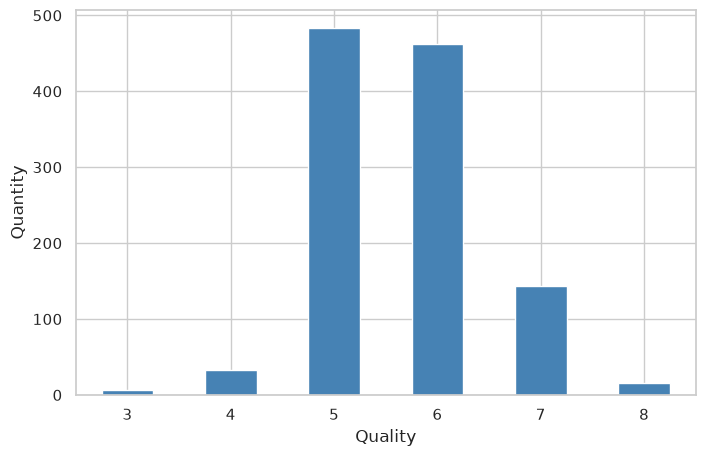

In [6]:
quality_counts = df_clean["quality"].value_counts().sort_index()
display(
    pd.DataFrame(
        {
            "count": quality_counts,
            "share_%": (quality_counts / len(df_clean) * 100).round(2),
        }
    )
)
quality_counts.plot(kind="bar", color="steelblue")
plt.xlabel("Quality")
plt.ylabel("Quantity")
plt.xticks(rotation=0)
plt.show()

## Бинарная целевая переменная

Для задачи классификации часто объединяют оценки: `quality > 5` — хорошее вино, остальные — обычное. Это позволяет увидеть баланс двух классов.

In [7]:
df_clean["quality_binary"] = (df_clean["quality"] > 5).astype(int)
print("0 — quality <= 5, 1 — quality > 5")
display(
    df_clean["quality_binary"]
    .value_counts()
    .rename(index={0: "quality <= 5", 1: "quality > 5"})
)

0 — quality <= 5, 1 — quality > 5


quality_binary
quality > 5     621
quality <= 5    522
Name: count, dtype: int64

## Распределения числовых признаков

Гистограммы помогают увидеть диапазоны, асимметрию и возможные необычные значения признаков.

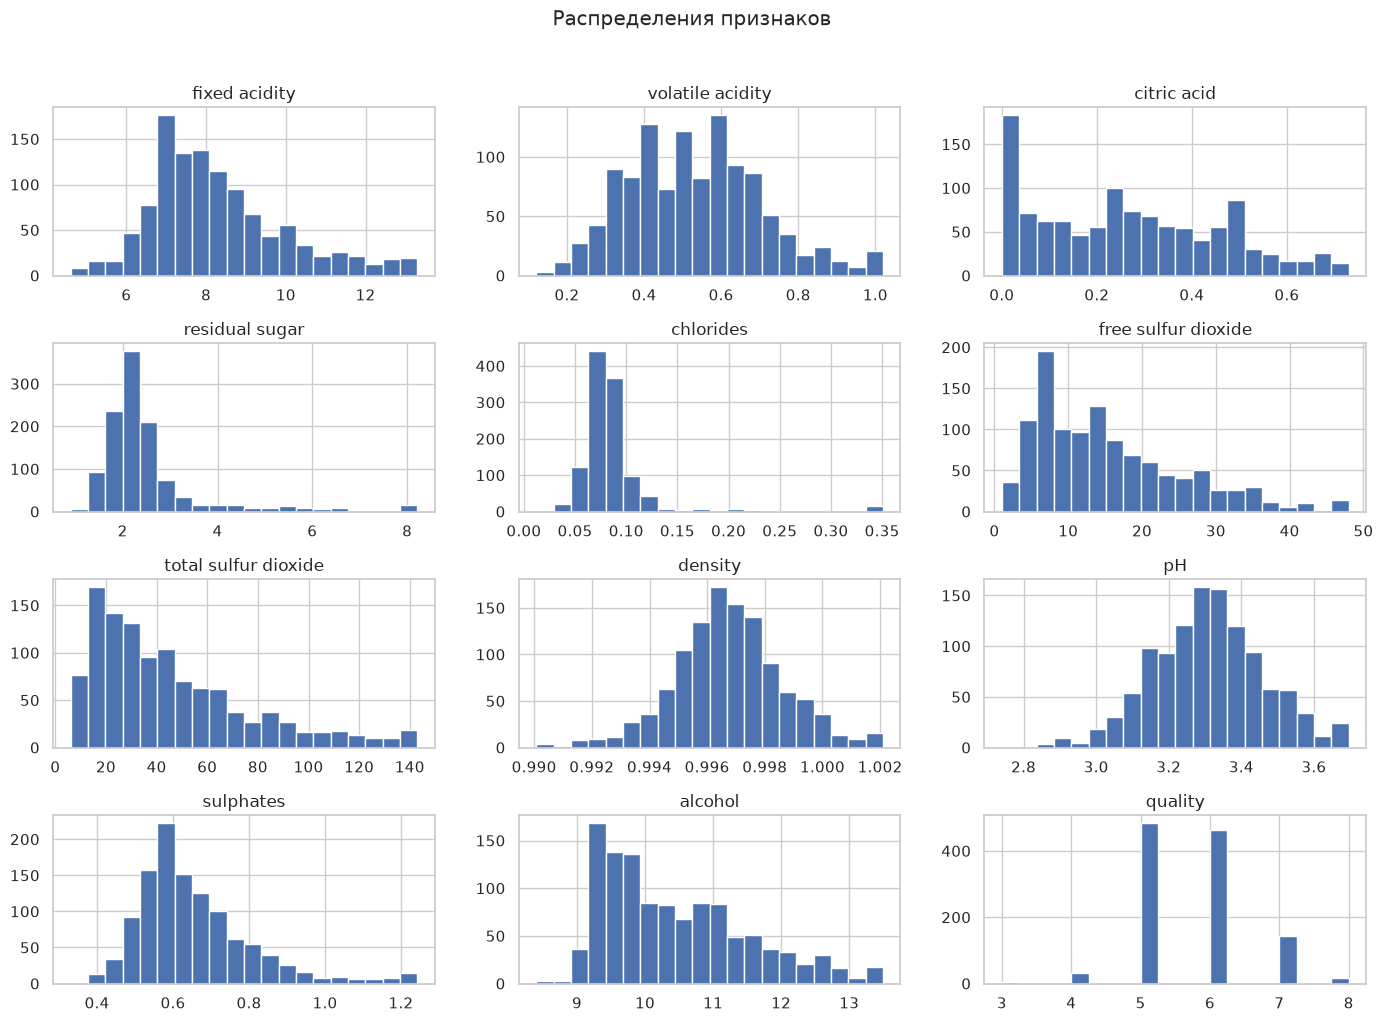

In [23]:
df_cleaned = df_analysis.clip(upper=df_analysis.quantile(0.99), axis=1)
df_cleaned.hist(bins=20, figsize=(14, 10))
plt.suptitle("Распределения признаков", y=1.02)
plt.tight_layout()
plt.show()

## Выбросы

Boxplot показывает медиану, межквартильный диапазон и потенциальные выбросы. Выброс не всегда является ошибкой, поэтому его нужно интерпретировать с учетом предметной области.

In [25]:
# Убираем целевую переменную и технический идентификатор
feature_cols = [
    col
    for col in df_clean.select_dtypes(include="number").columns
    if col not in ["quality", "quality_binary", "Id"]
]
print(*feature_cols, sep="\n")
df_features = df_clean[feature_cols]

fixed acidity
volatile acidity
citric acid
residual sugar
chlorides
free sulfur dioxide
total sulfur dioxide
density
pH
sulphates
alcohol


In [10]:
outlier_counts = {}

for col in feature_cols:
    q1 = df_features[col].quantile(0.25)
    q3 = df_features[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outlier_counts[col] = (
        (df_features[col] < lower) | (df_features[col] > upper)
    ).sum()

display(pd.Series(outlier_counts, name="outlier_count").sort_values(ascending=False))

residual sugar          110
chlorides                77
fixed acidity            44
sulphates                43
total sulfur dioxide     40
density                  36
pH                       20
free sulfur dioxide      18
volatile acidity         14
alcohol                  12
citric acid               1
Name: outlier_count, dtype: int64

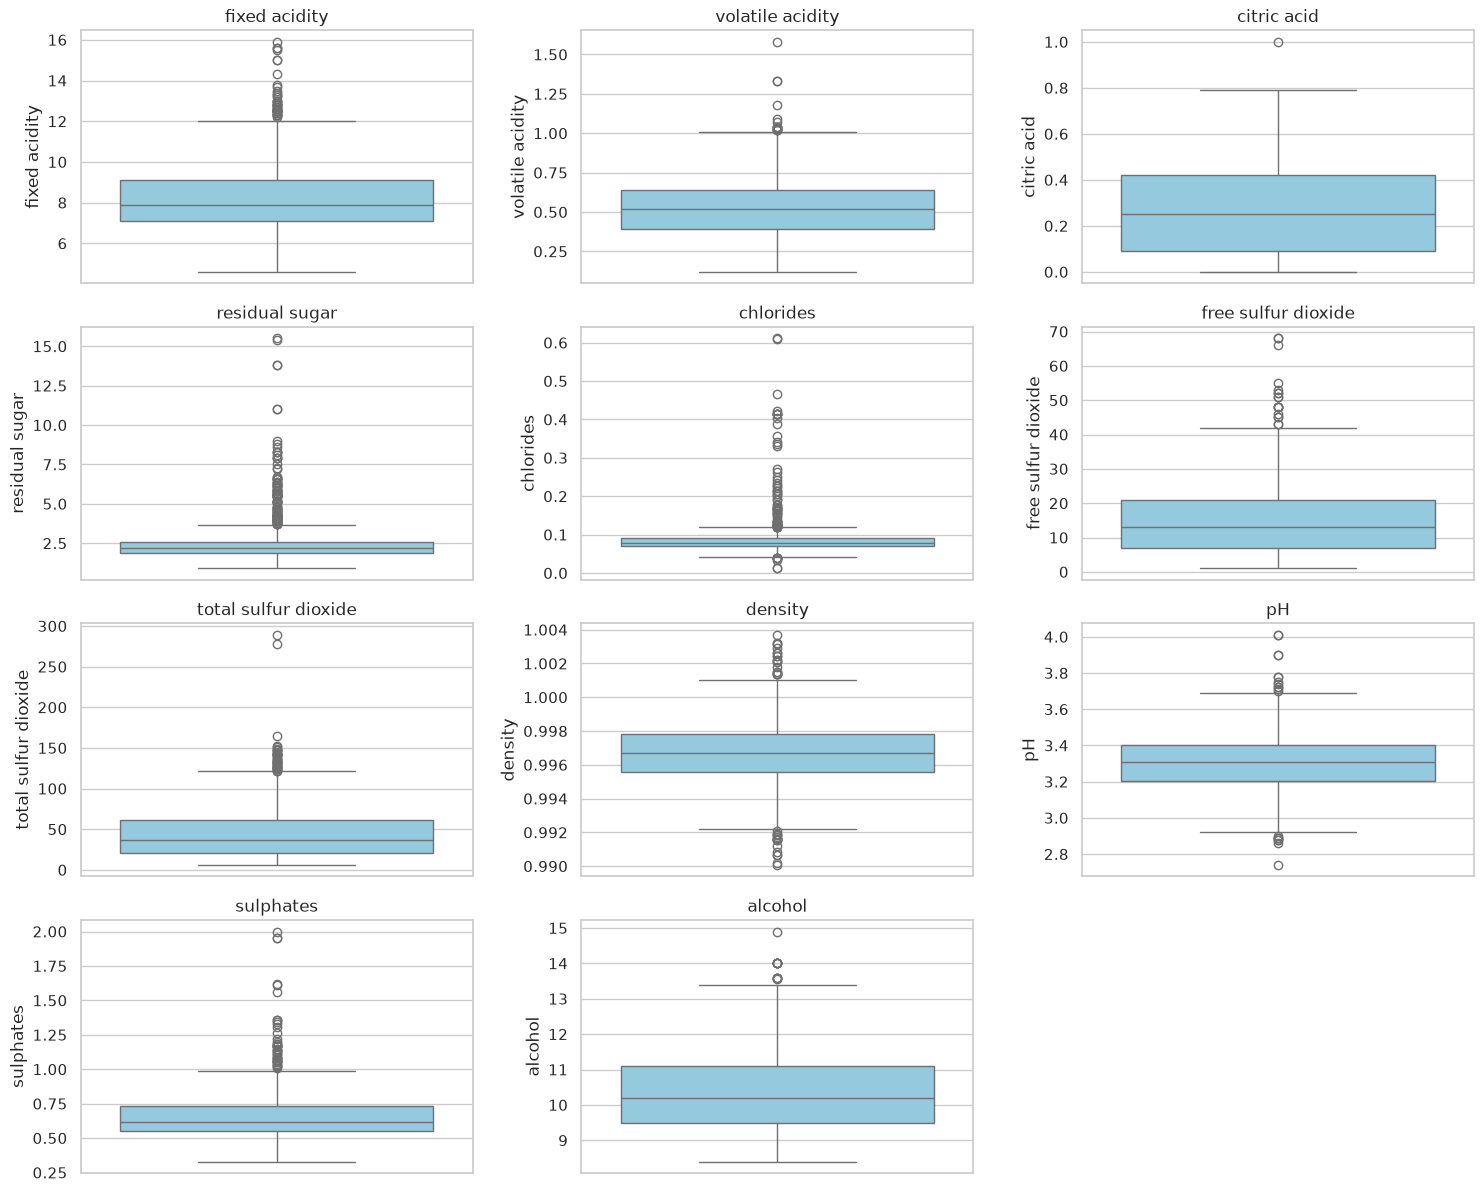

In [11]:
fig, axes = plt.subplots((len(feature_cols) + 2) // 3, 3, figsize=(15, 12))
for ax, col in zip(axes.flat, feature_cols):
    sns.boxplot(data=df_analysis, y=col, ax=ax, color="skyblue")
    ax.set_title(col)
for ax in axes.flat[len(feature_cols) :]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

## Сравнение признаков по качеству

Группировка по `quality` позволяет понять, какие химические характеристики отличаются у вин с разными оценками.

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
quality,,,,,,,,,,,
3,8.45,0.90,0.21,2.67,0.11,8.17,24.50,1.0,3.36,0.55,9.69
4,7.81,0.70,0.17,2.57,0.09,14.85,40.61,1.0,3.39,0.64,10.26
5,8.16,0.59,0.24,2.54,0.09,16.61,55.30,1.0,3.30,0.61,9.90
6,8.32,0.50,0.26,2.44,0.09,15.22,39.94,1.0,3.32,0.68,10.66
7,8.85,0.39,0.39,2.76,0.08,14.54,37.49,1.0,3.29,0.74,11.48
8,8.81,0.41,0.43,2.64,0.07,11.06,29.38,1.0,3.24,0.77,11.94


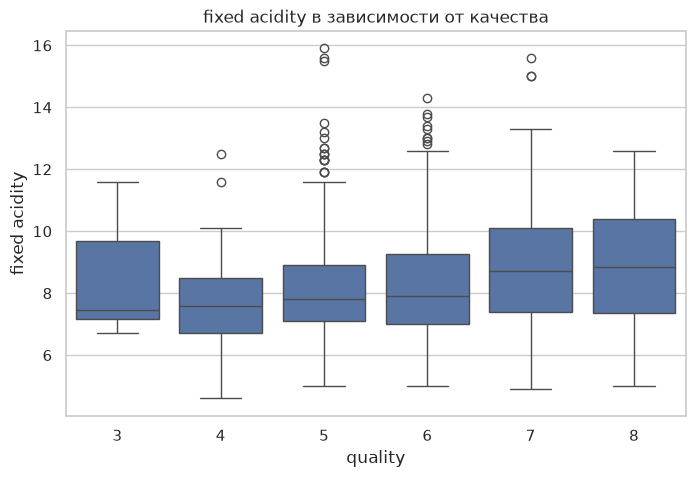

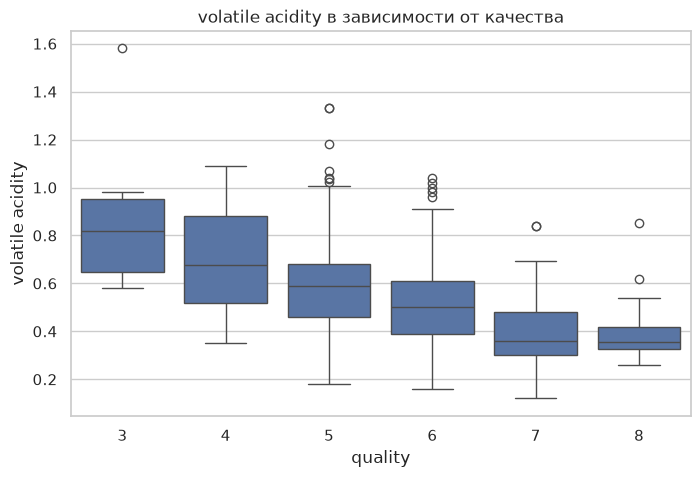

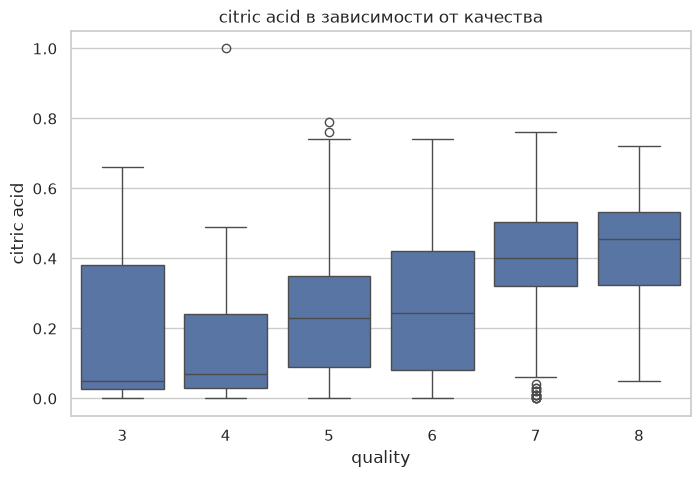

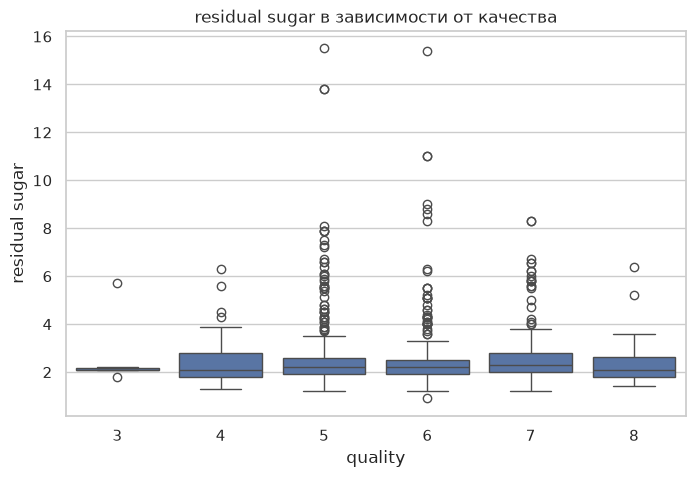

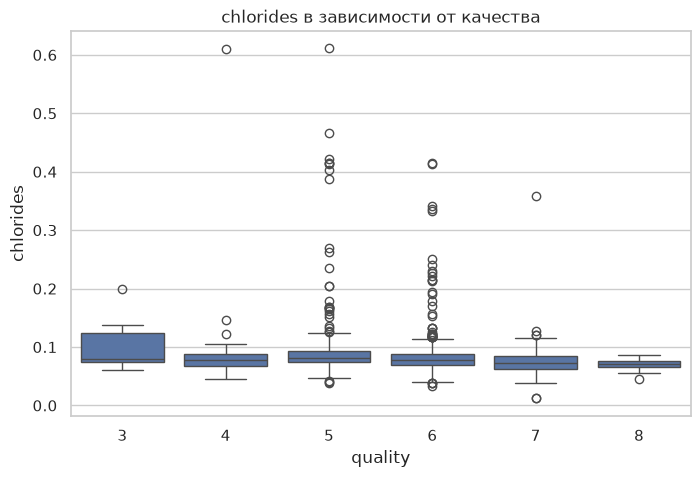

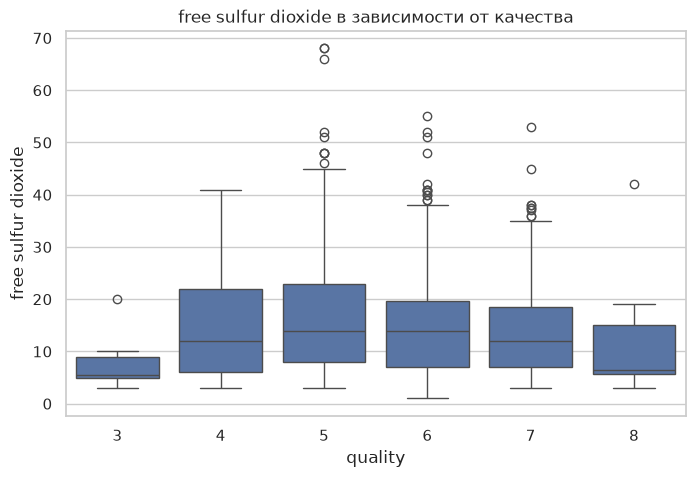

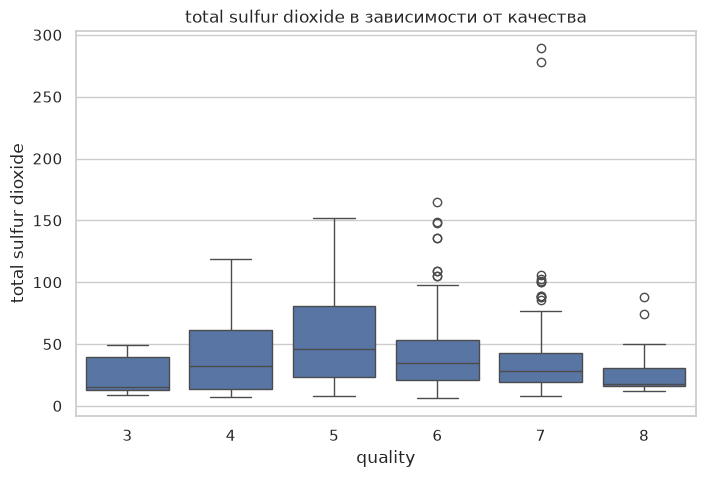

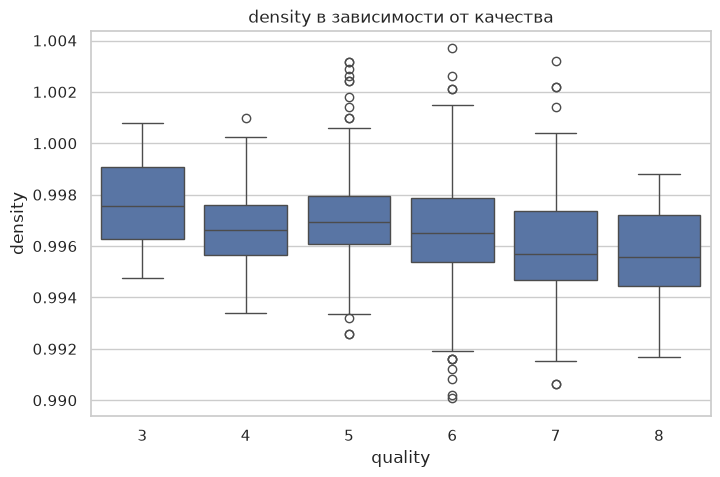

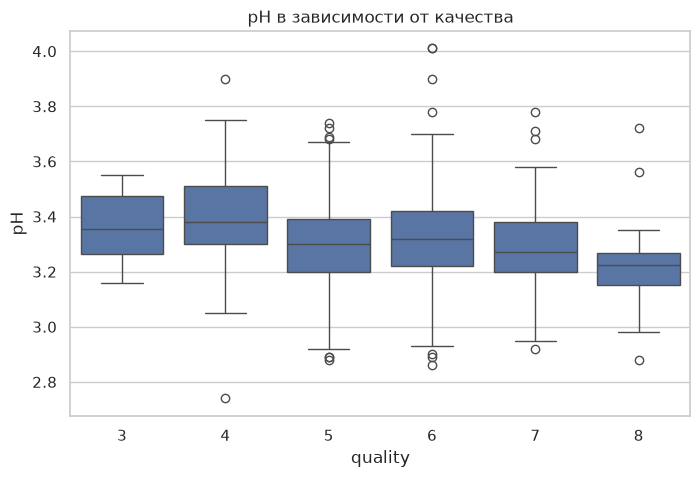

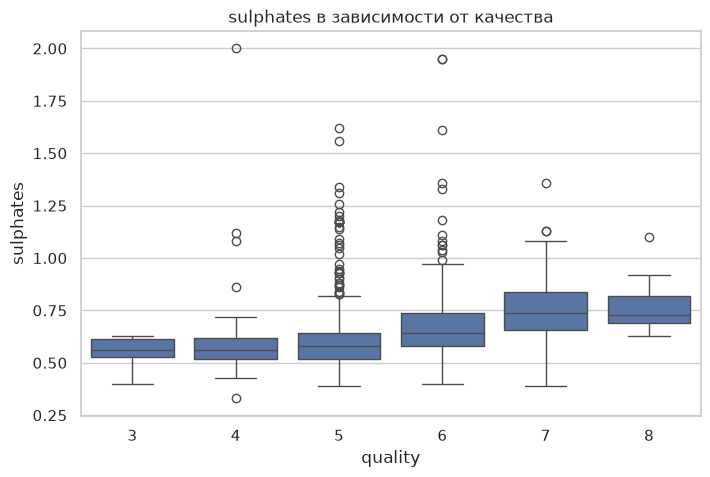

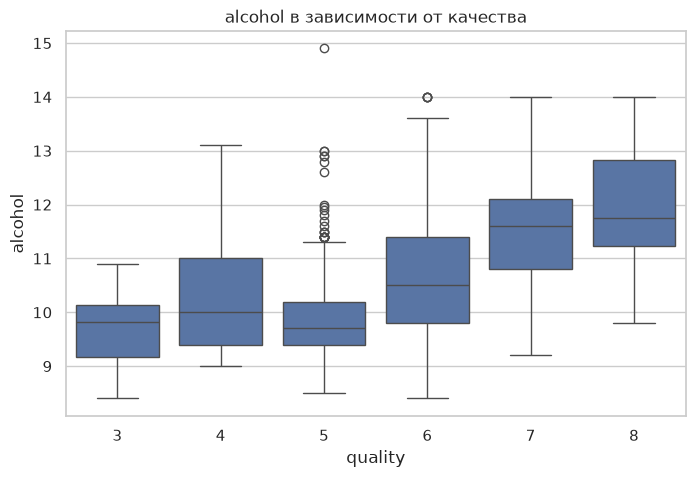

In [12]:
display(df_analysis.groupby("quality").mean(numeric_only=True).round(2))

for col in feature_cols:
    if col in df_clean.columns:
        plt.figure(figsize=(8, 5))
        sns.boxplot(data=df_clean, x="quality", y=col)
        plt.title(f"{col} в зависимости от качества")
        plt.show()

## Корреляция признаков

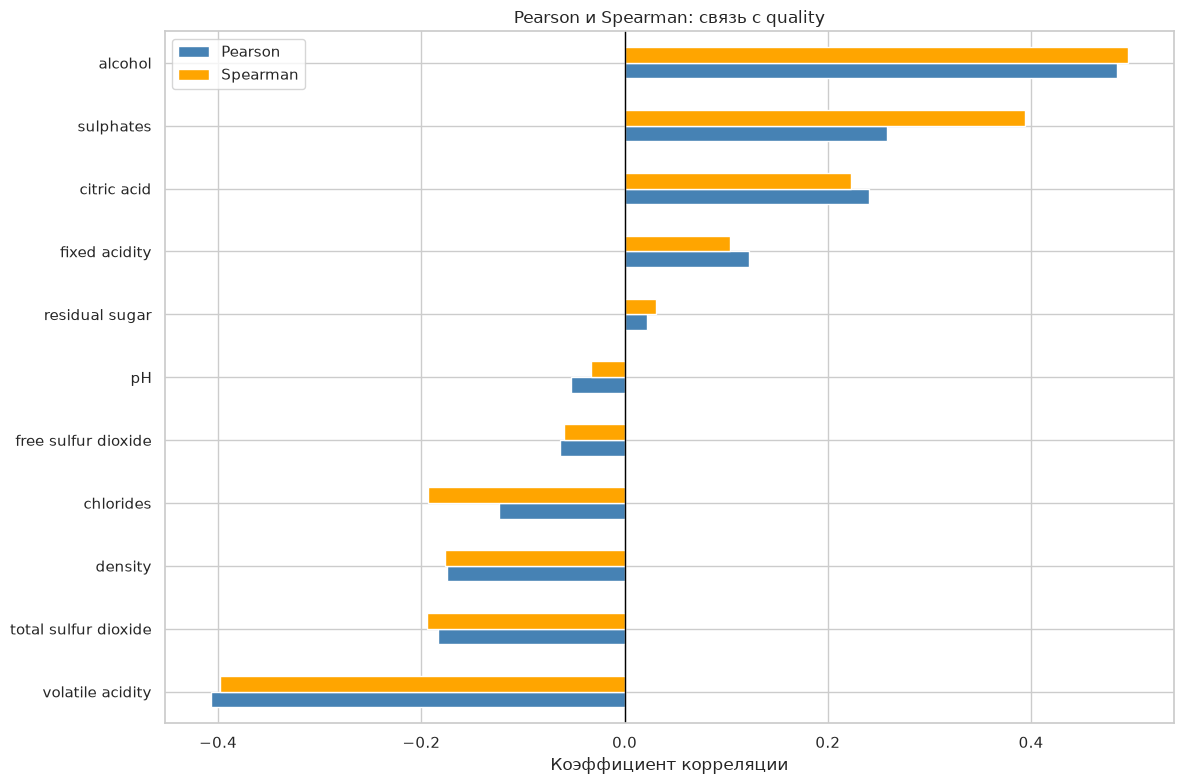

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

pearson = df_analysis.corr(method="pearson", numeric_only=True)
spearman = df_analysis.corr(method="spearman", numeric_only=True)
# Убираем саму quality: её корреляция с самой собой всегда равна 1
pearson_quality = pearson["quality"].drop("quality").sort_values()

spearman_quality = spearman["quality"].drop("quality").sort_values()

corr_comparison = pd.DataFrame(
    {"Pearson": pearson_quality, "Spearman": spearman_quality}
)

corr_comparison = corr_comparison.sort_values("Pearson")

corr_comparison.plot(kind="barh", figsize=(12, 8), color=["steelblue", "orange"])

plt.axvline(0, color="black", linewidth=1)
plt.title("Pearson и Spearman: связь с quality")
plt.xlabel("Коэффициент корреляции")
plt.ylabel("")
plt.legend()
plt.tight_layout()
plt.show()

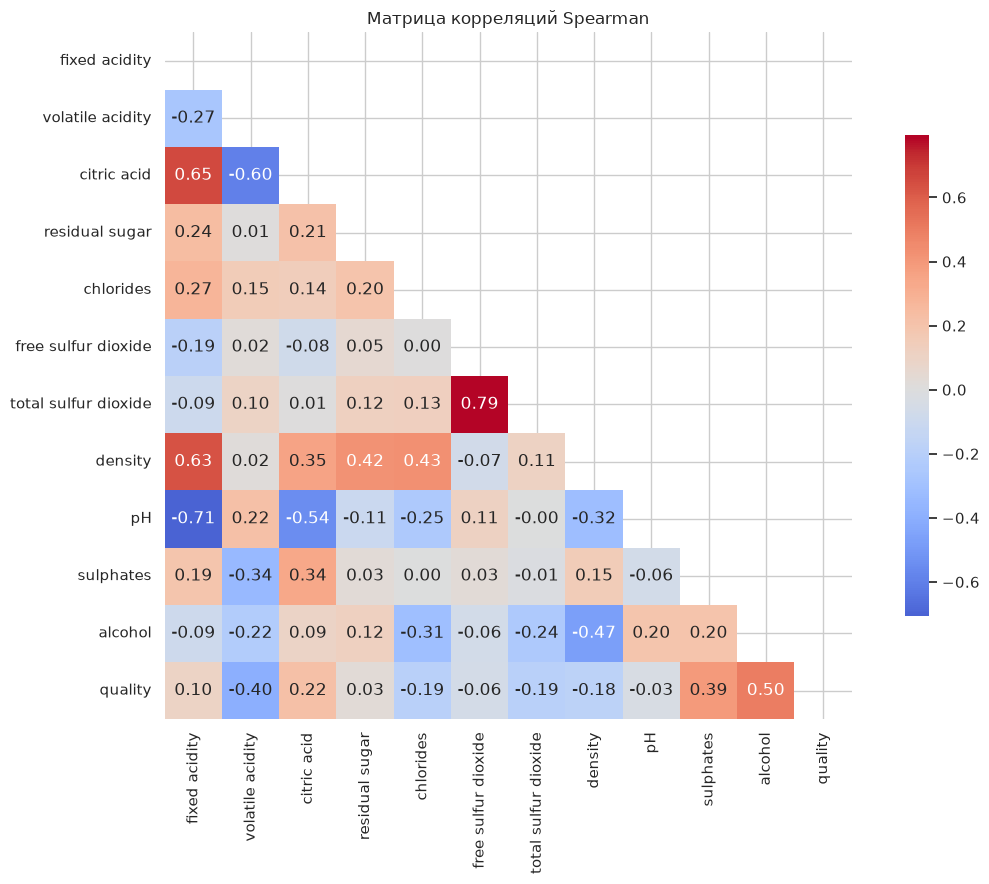

In [14]:
def plot_correlation_heatmap(corr_matrix, title):
    mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

    plt.figure(figsize=(12, 9))
    sns.heatmap(
        corr_matrix,
        mask=mask,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        center=0,
        square=True,
        cbar_kws={"shrink": 0.7},
    )

    plt.title(title)
    plt.tight_layout()
    plt.show()


# plot_correlation_heatmap(pearson, 'Матрица корреляций Pearson')
plot_correlation_heatmap(spearman, "Матрица корреляций Spearman")

## Взаимосвязи наиболее важных признаков

Pairplot позволяет одновременно посмотреть распределения и попарные зависимости выбранных признаков. Выбраны признаки, которые часто оказываются связанными с качеством вина.

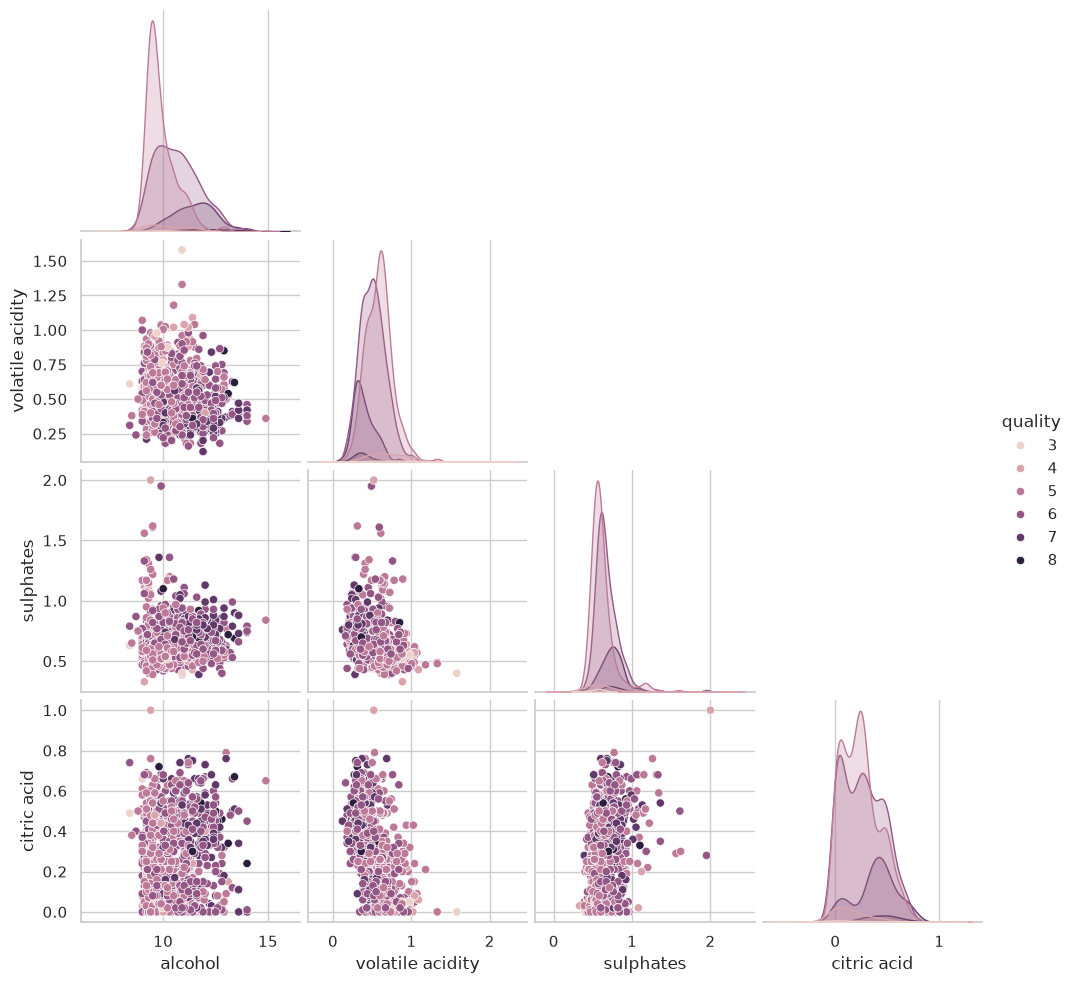

In [27]:
pair_cols = [
    'alcohol',
    'volatile acidity',
    'sulphates',
    'citric acid'
]

sns.pairplot(
    df_clean,
    vars=pair_cols,
    hue='quality',
    corner=True,
)

plt.show()

In [16]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

X = df_clean[feature_cols].copy()

vif = pd.DataFrame({
    'feature': X.columns,
    'VIF': [
        variance_inflation_factor(X.values, i)
        for i in range(X.shape[1])
    ]
})

display(vif.sort_values('VIF', ascending=False).round(2))

,feature,VIF
0,fixed acidity,7.78
7,density,6.60
8,pH,3.39
2,citric acid,3.22
10,alcohol,3.18
6,total sulfur dioxide,2.10
5,free sulfur dioxide,1.91
1,volatile acidity,1.78
3,residual sugar,1.74
4,chlorides,1.54


## Асимметрия распределений

Коэффициент асимметрии показывает, насколько распределение отклоняется от симметричного. Сильная асимметрия может потребовать преобразования признака перед моделированием.

In [17]:
skewness = (
    df_analysis.select_dtypes(include="number").skew().sort_values(ascending=False)
)
skewness = skewness[skewness.abs() > 1.0]  # Фильтруем признаки с сильной асимметрией
display(skewness.to_frame("skewness"))

,skewness
chlorides,6.026360
residual sugar,4.361096
sulphates,2.497266
total sulfur dioxide,1.665766
free sulfur dioxide,1.231261
fixed acidity,1.044930
